# 05 · Baselines and Logistic Regression

**What this notebook covers**

- Dummy baselines (most frequent, stratified)
- Logistic Regression grid search over `C` and `class_weight`
- Regularisation path plot
- Overfitting check (train vs CV score)
- Odds ratios and top drivers
- Sensitivity checks: reduced input set and L1 penalty

## 1. Environment setup
### 1.1 Imports
Standard model-notebook imports plus the estimator-specific ones.

In [1]:
import hashlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score, brier_score_loss, f1_score, make_scorer,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

### 1.2 Configuration
Every tunable knob lives here. Lower the search budget for a quick dry run, but use
the defaults for the reported results.

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "05"
NOTEBOOK_NAME = "05_baseline_logistic_regression.ipynb"
CV_FOLDS = 5

VARIANTS = ["day_zero", "full_lifecycle"]
LOGREG_GRID = {
    "model__C": np.logspace(-3, 2, 11),
    "model__class_weight": ["balanced", None],
}
LOGREG_MAX_ITER = 3000

### 1.3 Project paths, shared constants and helpers

In [3]:
# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


In [4]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [5]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [6]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,3.2.0
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,0.51.0


## 2. Load Train and Dev features (contract-verified)
Inputs are hash-checked against `feature_spec.json`. The held-out evaluation split is
deliberately not loaded here.

In [7]:
# Load the shared feature contract and ONLY the Train and Dev feature files.
# The held-out split is intentionally never referenced in model notebooks
# (the validation gate in notebook 10 scans this notebook's source to prove it).
FEATURE_SPEC = load_json(PATHS["artifacts"] / "feature_spec.json")

TRAIN_PATH = PATHS["features"] / "train.csv"
DEV_PATH = PATHS["features"] / "dev.csv"
DATA_FILES_READ = [str(TRAIN_PATH.relative_to(PROJECT_ROOT)), str(DEV_PATH.relative_to(PROJECT_ROOT))]

INPUT_HASHES = {"train": sha256_file(TRAIN_PATH), "dev": sha256_file(DEV_PATH)}
for split_name, digest in INPUT_HASHES.items():
    expected = FEATURE_SPEC["file_hashes"][split_name]
    assert digest == expected, (
        f"{split_name} feature file hash mismatch - re-run notebook 04 before training models."
    )

train_df = read_frame(TRAIN_PATH)
dev_df = read_frame(DEV_PATH)

X_train = train_df.drop(columns=[TARGET, ID_COLUMN])
y_train = train_df[TARGET].astype(int)
X_dev = dev_df.drop(columns=[TARGET, ID_COLUMN])
y_dev = dev_df[TARGET].astype(int)
dev_ids = dev_df[ID_COLUMN]

assert not set(LEAKAGE_COLUMNS) & set(X_train.columns), "Leakage columns reached the model inputs."
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.4f}")
print(f"Dev:   {X_dev.shape}, positive rate {y_dev.mean():.4f}")

Train: (60996, 38), positive rate 0.2728
Dev:   (13071, 38), positive rate 0.2727


### 2.1 Shared model-notebook helpers
These do the same job in notebooks 05–09: the CV splitter, multi-metric scoring
(refit on PR-AUC), fold-score extraction and `persist_model_outputs`, which writes the
model card contract consumed by the validation gate and the evaluation notebooks.

In [8]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())


def build_scoring(include_probability_metrics: bool = True) -> dict:
    """Multi-metric scoring used by every model notebook (refit metric = PR-AUC)."""
    scoring = {
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc",
        "f1": make_scorer(f1_score, zero_division=0),
        "precision": make_scorer(precision_score, zero_division=0),
        "recall": make_scorer(recall_score, zero_division=0),
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
    }
    if include_probability_metrics:
        scoring["neg_brier"] = "neg_brier_score"
    return scoring


def load_preprocessor(family: str, variant: str):
    """Load an UNFITTED preprocessing template produced by notebook 04."""
    path = PATHS["preprocessors"] / f"preprocessor__{family}__{variant}.joblib"
    return clone(joblib.load(path))


def make_pipeline(estimator, family: str, variant: str) -> Pipeline:
    return Pipeline([("preprocess", load_preprocessor(family, variant)), ("model", estimator)])


def fold_scores_from_search(search, n_splits: int) -> pd.DataFrame:
    """Per-fold CV scores of the best candidate, read from cv_results_ (no refit needed)."""
    results, best = search.cv_results_, search.best_index_
    metrics = sorted({key.split("_test_", 1)[1] for key in results if key.startswith("split0_test_")})
    rows = []
    for fold in range(n_splits):
        row = {"fold": fold}
        for metric in metrics:
            row[metric] = results[f"split{fold}_test_{metric}"][best]
            train_key = f"split{fold}_train_{metric}"
            if train_key in results:
                row[f"train_{metric}"] = results[train_key][best]
        rows.append(row)
    return tidy_fold_scores(pd.DataFrame(rows))


def fold_scores_from_cross_validate(cv_output: dict) -> pd.DataFrame:
    frame = pd.DataFrame({
        key.replace("test_", "", 1) if key.startswith("test_") else key: values
        for key, values in cv_output.items() if key.startswith(("test_", "train_"))
    })
    frame.insert(0, "fold", range(len(frame)))
    return tidy_fold_scores(frame)


def tidy_fold_scores(frame: pd.DataFrame) -> pd.DataFrame:
    for prefix in ("", "train_"):
        if f"{prefix}neg_brier" in frame:
            frame[f"{prefix}brier"] = -frame.pop(f"{prefix}neg_brier")
    return frame


def summarise_folds(fold_scores: pd.DataFrame) -> dict:
    metric_cols = [c for c in fold_scores.columns if c != "fold" and not c.startswith("train_")]
    return {m: {"mean": float(fold_scores[m].mean()), "std": float(fold_scores[m].std(ddof=1))} for m in metric_cols}


def quick_dev_metrics(y_true, y_proba) -> dict:
    """Lightweight sanity metrics only - the official evaluation happens in notebook 11."""
    return {
        "pr_auc": float(average_precision_score(y_true, y_proba)),
        "roc_auc": float(roc_auc_score(y_true, y_proba)),
        "brier": float(brier_score_loss(y_true, y_proba)),
    }


def persist_model_outputs(*, model_key, variant, family, pipeline, fold_scores, dev_proba,
                          best_params, imbalance_strategy, fit_seconds, search=None,
                          cv_rows=None, extra=None) -> dict:
    """Write the model + the standard model-card contract consumed by notebooks 10-14."""
    model_id = f"{model_key}__{variant}"
    out_dir = PATHS["model_outputs"] / model_id
    out_dir.mkdir(parents=True, exist_ok=True)

    model_path = PATHS["models"] / f"{model_id}.joblib"
    joblib.dump(pipeline, model_path)

    fold_scores.to_csv(out_dir / "cv_fold_scores.csv", index=False)
    pd.DataFrame({ID_COLUMN: dev_ids.values, "y_true": y_dev.values, "y_proba": dev_proba}).to_csv(
        out_dir / "dev_predictions.csv", index=False
    )
    if search is not None:
        pd.DataFrame(search.cv_results_).drop(columns=["params"], errors="ignore").to_csv(
            out_dir / "search_results.csv", index=False
        )

    card = {
        "model_id": model_id,
        "model_key": model_key,
        "variant": variant,
        "notebook": NOTEBOOK_NAME,
        "preprocessor_family": family,
        "imbalance_strategy": imbalance_strategy,
        "cv": {
            "type": type(CV).__name__,
            "n_splits": CV.get_n_splits(),
            "shuffle": bool(CV.shuffle),
            "random_state": CV.random_state,
            "n_rows": int(cv_rows if cv_rows is not None else len(X_train)),
        },
        "n_fit_rows": int(len(X_train)),
        "n_dev_rows": int(len(X_dev)),
        "data_files_read": DATA_FILES_READ,
        "input_hashes": INPUT_HASHES,
        "best_params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in best_params.items()},
        "cv_summary": summarise_folds(fold_scores),
        "dev_quick": quick_dev_metrics(y_dev, dev_proba),
        "fit_seconds": round(float(fit_seconds), 2),
        "model_path": str(model_path.relative_to(PROJECT_ROOT)),
        "model_sha256": sha256_file(model_path),
        "random_state": RANDOM_STATE,
        "library_versions": LIBRARY_VERSIONS,
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        **(extra or {}),
    }
    save_json(card, out_dir / "model_card.json")
    print(f"[{model_id}] CV PR-AUC {card['cv_summary']['pr_auc']['mean']:.4f} "
          f"± {card['cv_summary']['pr_auc']['std']:.4f} | Dev PR-AUC {card['dev_quick']['pr_auc']:.4f}")
    return card

## 3. Dummy baselines
### 3.1 Train and cross-validate both strategies
- `most_frequent` always predicts "not cancelled": the accuracy floor (~72.7 %), with
  zero recall.
- `stratified` predicts at random with the class prior: the no-skill PR-AUC floor
  (≈ prevalence).

They go through the same preprocessing pipeline as every other model, so the
validation gate treats them uniformly. Variant = `baseline` (they ignore features).

In [9]:
baseline_cards = {}
for strategy in ["most_frequent", "stratified"]:
    pipeline = make_pipeline(DummyClassifier(strategy=strategy, random_state=RANDOM_STATE), "linear", "day_zero")
    start = time.perf_counter()
    cv_output = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=build_scoring(), return_train_score=True)
    pipeline.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    baseline_cards[strategy] = persist_model_outputs(
        model_key=f"dummy_{strategy}", variant="baseline", family="linear", pipeline=pipeline,
        fold_scores=fold_scores_from_cross_validate(cv_output), dev_proba=pipeline.predict_proba(X_dev)[:, 1],
        best_params={"strategy": strategy}, imbalance_strategy="none", fit_seconds=elapsed,
    )

[dummy_most_frequent__baseline] CV PR-AUC 0.2728 ± 0.0000 | Dev PR-AUC 0.2727
[dummy_stratified__baseline] CV PR-AUC 0.2735 ± 0.0013 | Dev PR-AUC 0.2704


### 3.2 Baseline summary
Every real model must clearly beat these numbers on PR-AUC and recall, not just accuracy.

In [10]:
pd.DataFrame({name: {metric: values["mean"] for metric, values in card["cv_summary"].items()}
              for name, card in baseline_cards.items()}).round(4)

,most_frequent,stratified
pr_auc,0.2728,0.2735
roc_auc,0.5000,0.5017
f1,0.0000,0.2720
precision,0.0000,0.2753
recall,0.0000,0.2687
balanced_accuracy,0.5000,0.5017
accuracy,0.7272,0.6076
brier,0.2728,0.3924


## 4. Logistic Regression
### 4.1 Grid search per variant
A grid search is appropriate for this small 2-parameter space (11 × 2 = 22 candidates ×
5 folds). Convergence of the refitted model is asserted (solver iterations < `max_iter`),
not left to warnings that parallel workers would swallow.

In [11]:
logreg_searches, logreg_cards = {}, {}
for variant in VARIANTS:
    pipeline = make_pipeline(LogisticRegression(max_iter=LOGREG_MAX_ITER, random_state=RANDOM_STATE), "linear", variant)
    search = GridSearchCV(pipeline, LOGREG_GRID, scoring=build_scoring(), refit="pr_auc", cv=CV,
                          n_jobs=-1, return_train_score=True)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    # Warnings raised inside parallel workers do not reach this process, so convergence is
    # verified directly on the refitted model: iterations used must stay below max_iter.
    n_iterations = int(search.best_estimator_.named_steps["model"].n_iter_.max())
    converged = n_iterations < LOGREG_MAX_ITER
    print(f"[{variant}] best params {search.best_params_} | solver iterations {n_iterations} (converged: {converged})")
    assert converged, "Logistic Regression did not converge - increase LOGREG_MAX_ITER."

    logreg_searches[variant] = search
    logreg_cards[variant] = persist_model_outputs(
        model_key="logreg", variant=variant, family="linear", pipeline=search.best_estimator_,
        fold_scores=fold_scores_from_search(search, CV_FOLDS),
        dev_proba=search.best_estimator_.predict_proba(X_dev)[:, 1],
        best_params=search.best_params_, imbalance_strategy="class_weight", fit_seconds=elapsed, search=search,
        extra={"solver_iterations": n_iterations, "converged": converged},
    )

[day_zero] best params {'model__C': np.float64(0.1), 'model__class_weight': None} | solver iterations 73 (converged: True)
[logreg__day_zero] CV PR-AUC 0.6507 ± 0.0060 | Dev PR-AUC 0.6507
[full_lifecycle] best params {'model__C': np.float64(0.03162277660168379), 'model__class_weight': None} | solver iterations 84 (converged: True)
[logreg__full_lifecycle] CV PR-AUC 0.7013 ± 0.0063 | Dev PR-AUC 0.7030


### 4.2 Regularisation path: CV PR-AUC vs `C`, by class weighting
Two series on one axis with ±1 SD bands. Two questions:
- Where does performance plateau? (Choose the simplest `C` on the plateau.)
- Does `balanced` weighting help *ranking* (PR-AUC)? It mostly shifts probabilities;
  the effect on recall at a threshold is handled in notebook 12.

Saved figure -> reports/figures/05_logreg_regularisation_path.png


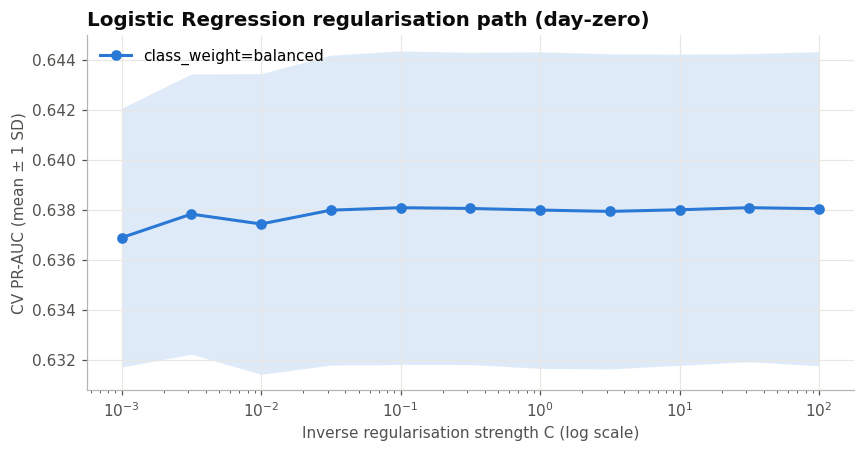

In [12]:
results = pd.DataFrame(logreg_searches["day_zero"].cv_results_)
results["class_weight"] = results["param_model__class_weight"].astype(str)
fig, ax = plt.subplots(figsize=(9, 4.2))
for color, (weight, group) in zip(SERIES_COLORS, results.groupby("class_weight")):
    group = group.sort_values("param_model__C")
    c_values = group["param_model__C"].astype(float)
    ax.plot(c_values, group["mean_test_pr_auc"], marker="o", markersize=6, color=color, label=f"class_weight={weight}")
    ax.fill_between(c_values, group["mean_test_pr_auc"] - group["std_test_pr_auc"],
                    group["mean_test_pr_auc"] + group["std_test_pr_auc"], color=color, alpha=0.15, linewidth=0)
ax.set_xscale("log")
ax.set_xlabel("Inverse regularisation strength C (log scale)")
ax.set_ylabel("CV PR-AUC (mean ± 1 SD)")
ax.set_title("Logistic Regression regularisation path (day-zero)", loc="left")
ax.legend()
save_figure(fig, "logreg_regularisation_path")
plt.show()

### 4.3 Over-fitting check: train vs validation fold scores
For a well-regularised linear model the gap should be small. A large gap would
point to an overly high `C`.

In [13]:
pd.DataFrame({
    variant: {
        "cv_pr_auc": card["cv_summary"]["pr_auc"]["mean"],
        "train_pr_auc": pd.read_csv(PATHS["model_outputs"] / f"logreg__{variant}" / "cv_fold_scores.csv")["train_pr_auc"].mean(),
    }
    for variant, card in logreg_cards.items()
}).T.assign(gap=lambda d: d["train_pr_auc"] - d["cv_pr_auc"]).round(4)

,cv_pr_auc,train_pr_auc,gap
day_zero,0.6507,0.6527,0.0020
full_lifecycle,0.7013,0.7031,0.0019


## 5. Interpretation: odds ratios (day-zero model)
### 5.1 Coefficient table
Inputs are standardised, so each numeric odds ratio is *per one standard deviation*.
For one-hot features it is relative to the average category. Odds ratios show
association, not causation (docs/07 §7.3).

**Caveat (collinearity):** `total_nights`, `total_guests` and `total_previous_bookings`
are exact sums of other inputs (notebook 04 §4.4, infinite VIF). The model still fits
well because of the L2 penalty, but the weight is shared across each sum and its parts,
so those odds ratios must not be read one by one. For example, `previous_cancellations`
can look slightly protective here even though guests with a prior cancellation cancel
far more often (notebook 03 §7). Section 6 refits the model without the raw parts and
gives odds ratios that can be read directly.

In [14]:
best_day_zero = logreg_searches["day_zero"].best_estimator_
feature_names = best_day_zero.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": best_day_zero.named_steps["model"].coef_.ravel(),
}).assign(odds_ratio=lambda d: np.exp(d["coefficient"]), abs_coef=lambda d: d["coefficient"].abs())
coefficients = coefficients.sort_values("abs_coef", ascending=False).drop(columns="abs_coef")
coefficients.to_csv(PATHS["tables"] / "05_logreg_day_zero_odds_ratios.csv", index=False)
coefficients.head(20).round(4)

,feature,coefficient,odds_ratio
40,cat_low__deposit_type_No Deposit,-1.5192,0.2189
70,cat_high__country_PRT,1.3930,4.0268
41,cat_low__deposit_type_Non Refund,1.2325,3.4299
77,cat_high__agent_28,-1.1804,0.3071
74,cat_high__agent_240,1.1558,3.1766
80,cat_high__agent_9,1.1325,3.1033
87,cat_high__company_223,-0.7772,0.4597
78,cat_high__agent_7,-0.6740,0.5096
11,num__total_of_special_requests,-0.6227,0.5365
45,cat_low__customer_type_Transient,0.6007,1.8234


### 5.2 Top drivers chart
Diverging encoding: orange raises the odds of cancellation, blue lowers them. The
x-axis is the log-odds coefficient, so effects are symmetric around zero.

Saved figure -> reports/figures/05_logreg_top_coefficients.png


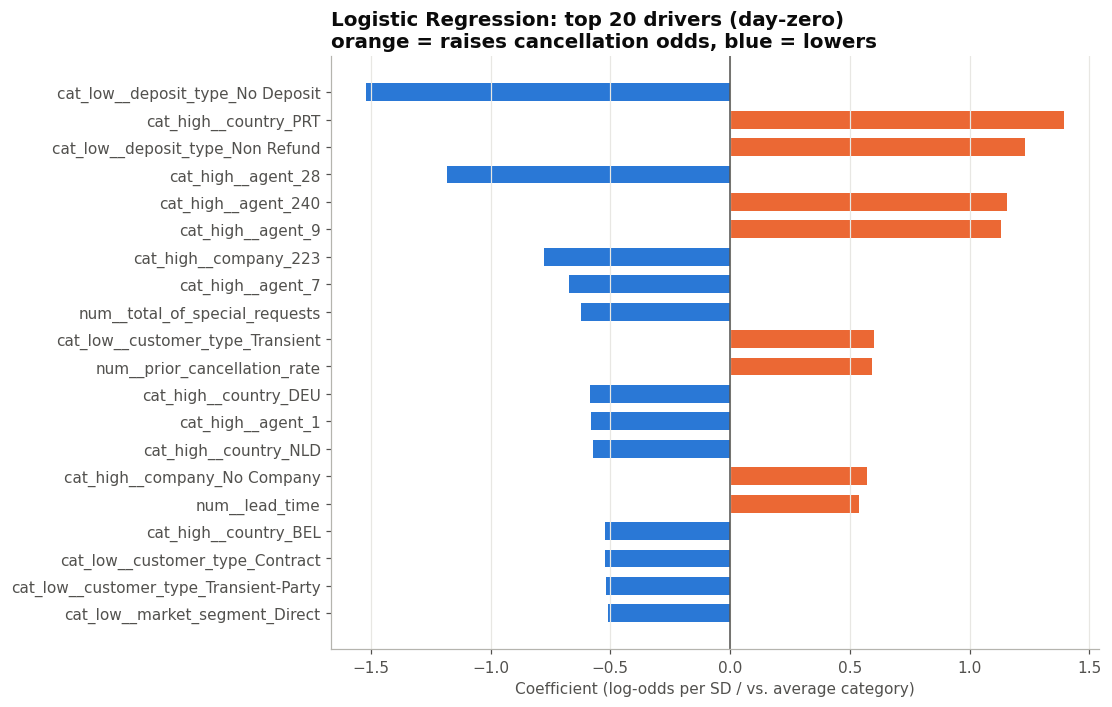

In [15]:
top = coefficients.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
colors = [COLORS["canceled"] if c > 0 else COLORS["not_canceled"] for c in top["coefficient"]]
ax.barh(top["feature"], top["coefficient"], color=colors, height=0.65)
ax.axvline(0, color=COLORS["ink_muted"], linewidth=1)
ax.set_xlabel("Coefficient (log-odds per SD / vs. average category)")
ax.set_title("Logistic Regression: top 20 drivers (day-zero)\norange = raises cancellation odds, blue = lowers", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "logreg_top_coefficients")
plt.show()

## 6. Sensitivity checks (Logistic Regression, day-zero)
Two checks on the reported model, all with the same CV folds and the tuned `C` and
`class_weight` read from the saved model:

- **Reduced input set:** drop the raw parts of the three exact sums
  (`stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children`, `babies`,
  `previous_cancellations`, `previous_bookings_not_canceled`). The totals,
  `weekend_night_ratio`, `is_family` and `prior_cancellation_rate` keep the information.
- **L1 penalty:** an embedded feature-selection method. It pushes the weights of
  unhelpful inputs to exactly zero.

**How to run:** run sections 1 and 2, then this section. Do not re-run sections 3 and
4: they rewrite the saved models and model cards, which notebook 14 has locked. This
section only reads the saved model and writes report files.

### 6.1 Setup

In [16]:
SENSITIVITY_VARIANT = "day_zero"
REDUNDANT_PARTS = [
    "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies",
    "previous_cancellations", "previous_bookings_not_canceled",
]

saved_logreg = joblib.load(PATHS["models"] / f"logreg__{SENSITIVITY_VARIANT}.joblib")
saved_params = saved_logreg.named_steps["model"].get_params()
BEST_LOGREG_PARAMS = {"C": float(saved_params["C"]), "class_weight": saved_params["class_weight"]}
print(f"Tuned settings from the saved model: {BEST_LOGREG_PARAMS}")


def linear_preprocessor_without(columns_to_drop: list[str]):
    """Unfitted linear template from notebook 04 with some numeric inputs removed."""
    preprocessor = load_preprocessor("linear", SENSITIVITY_VARIANT)
    preprocessor.transformers = [(name, step, [c for c in cols if c not in columns_to_drop])
                                 for name, step, cols in preprocessor.transformers]
    return preprocessor


def logreg(**overrides) -> LogisticRegression:
    params = {**BEST_LOGREG_PARAMS, "max_iter": LOGREG_MAX_ITER, "random_state": RANDOM_STATE, **overrides}
    return LogisticRegression(**params)


# L1 in scikit-learn 1.8+: l1_ratio=1.0 with a solver that supports it ("saga").
L1_SETTINGS = {"l1_ratio": 1.0, "solver": "saga"}

Tuned settings from the saved model: {'C': 0.1, 'class_weight': None}


### 6.2 Cross-validated comparison
Same `CV` splitter as sections 3 and 4, so the folds match the reported model.

In [17]:
experiments = {
    "Full input set (reported)": Pipeline([("preprocess", linear_preprocessor_without([])), ("model", logreg())]),
    "Reduced input set": Pipeline([("preprocess", linear_preprocessor_without(REDUNDANT_PARTS)), ("model", logreg())]),
    "L1 penalty": Pipeline([("preprocess", linear_preprocessor_without([])), ("model", logreg(**L1_SETTINGS))]),
}

sensitivity_rows, sensitivity_folds = [], {}
for name, pipeline in experiments.items():
    start = time.perf_counter()
    cv_out = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=build_scoring(), n_jobs=-1)
    sensitivity_folds[name] = cv_out["test_pr_auc"]
    sensitivity_rows.append({
        "experiment": name,
        "pr_auc_mean": cv_out["test_pr_auc"].mean(), "pr_auc_std": cv_out["test_pr_auc"].std(ddof=1),
        "recall_mean": cv_out["test_recall"].mean(), "precision_mean": cv_out["test_precision"].mean(),
        "brier_mean": -cv_out["test_neg_brier"].mean(),
        "seconds": round(time.perf_counter() - start, 1),
    })
    print(f"{name:<28} CV PR-AUC {sensitivity_rows[-1]['pr_auc_mean']:.4f} ± {sensitivity_rows[-1]['pr_auc_std']:.4f}")

sensitivity = pd.DataFrame(sensitivity_rows).set_index("experiment")
reference = sensitivity.loc["Full input set (reported)"]
sensitivity["delta_pr_auc"] = sensitivity["pr_auc_mean"] - reference["pr_auc_mean"]
sensitivity["within_1_sd"] = sensitivity["delta_pr_auc"].abs() <= reference["pr_auc_std"]
sensitivity.to_csv(PATHS["tables"] / "05_sensitivity_checks.csv")
sensitivity.round(4)

Full input set (reported)    CV PR-AUC 0.6507 ± 0.0060
Reduced input set            CV PR-AUC 0.6506 ± 0.0062
L1 penalty                   CV PR-AUC 0.6501 ± 0.0059


,pr_auc_mean,pr_auc_std,recall_mean,precision_mean,brier_mean,seconds,delta_pr_auc,within_1_sd
experiment,,,,,,,,
Full input set (reported),0.6507,0.0060,0.4423,0.6661,0.1430,1.3,0.0000,True
Reduced input set,0.6506,0.0062,0.4426,0.6672,0.1430,1.2,-0.0001,True
L1 penalty,0.6501,0.0059,0.4400,0.6681,0.1431,79.2,-0.0006,True


### 6.3 Sensitivity chart
Dot = CV mean, whisker = ±1 SD. The shaded band is ±1 SD around the reported model.
A check inside the band performs the same as the reported model.

Saved figure -> reports/figures/05_logreg_sensitivity_checks.png


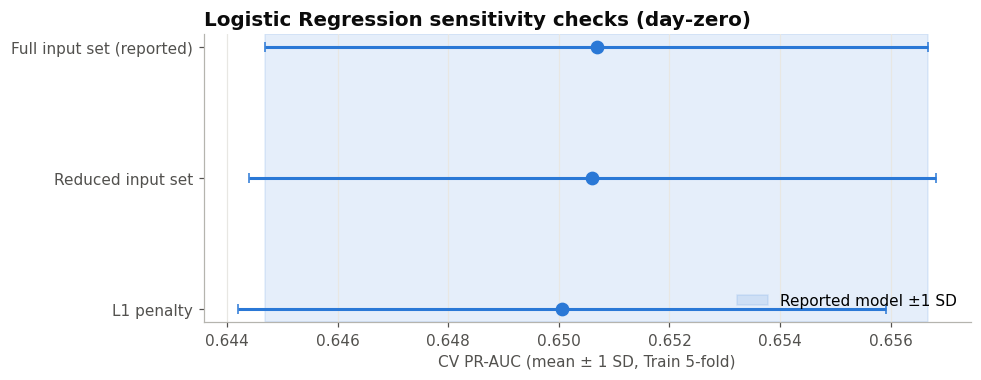

In [18]:
order = sensitivity.index[::-1]
fig, ax = plt.subplots(figsize=(9, 0.6 * len(order) + 1.6))
ax.axvspan(reference["pr_auc_mean"] - reference["pr_auc_std"], reference["pr_auc_mean"] + reference["pr_auc_std"],
           color=COLORS["not_canceled"], alpha=0.12, label="Reported model ±1 SD")
ax.errorbar(sensitivity.loc[order, "pr_auc_mean"], range(len(order)), xerr=sensitivity.loc[order, "pr_auc_std"],
            fmt="o", markersize=8, color=COLORS["not_canceled"], ecolor=COLORS["not_canceled"], elinewidth=2, capsize=3)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("CV PR-AUC (mean ± 1 SD, Train 5-fold)")
ax.set_title("Logistic Regression sensitivity checks (day-zero)", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_figure(fig, "logreg_sensitivity_checks")
plt.show()

### 6.4 Readable odds ratios (reduced input set) and L1 zero weights
The reduced model has no exact sums, so its odds ratios for stay length, party size and
booking history can be read one by one. The L1 model shows which encoded inputs it
drops entirely.

In [19]:
reduced_model = experiments["Reduced input set"].fit(X_train, y_train)
reduced_names = reduced_model.named_steps["preprocess"].get_feature_names_out()
reduced_coefficients = (
    pd.DataFrame({"feature": reduced_names, "coefficient": reduced_model.named_steps["model"].coef_.ravel()})
    .assign(odds_ratio=lambda d: np.exp(d["coefficient"]))
    .sort_values("coefficient", key=np.abs, ascending=False)
)
reduced_coefficients.to_csv(PATHS["tables"] / "05_logreg_reduced_odds_ratios.csv", index=False)

l1_model = experiments["L1 penalty"].fit(X_train, y_train)
l1_names = l1_model.named_steps["preprocess"].get_feature_names_out()
l1_weights = pd.Series(l1_model.named_steps["model"].coef_.ravel(), index=l1_names, name="coefficient")
l1_zero = l1_weights[l1_weights == 0].index.tolist()
pd.DataFrame({"feature": l1_zero}).to_csv(PATHS["tables"] / "05_logreg_l1_zero_coefficients.csv", index=False)
print(f"L1 set {len(l1_zero)} of {len(l1_weights)} encoded inputs to exactly zero:")
print(l1_zero)

numeric_view = reduced_coefficients[reduced_coefficients["feature"].str.startswith("num__")]
numeric_view.round(4)

L1 set 33 of 94 encoded inputs to exactly zero:
['num__arrival_date_week_number', 'num__stays_in_weekend_nights', 'num__children', 'num__previous_bookings_not_canceled', 'num__total_guests', 'cat_low__hotel_City Hotel', 'cat_low__meal_FB', 'cat_low__meal_Undefined', 'cat_low__market_segment_Aviation', 'cat_low__market_segment_Complementary', 'cat_low__market_segment_Corporate', 'cat_low__market_segment_Groups', 'cat_low__market_segment_Online TA', 'cat_low__market_segment_Undefined', 'cat_low__distribution_channel_Corporate', 'cat_low__distribution_channel_GDS', 'cat_low__distribution_channel_TA/TO', 'cat_low__distribution_channel_Undefined', 'cat_low__deposit_type_Refundable', 'cat_low__customer_type_Group', 'cat_low__arrival_season_Winter', 'cat_low__reserved_room_type_A', 'cat_low__reserved_room_type_B', 'cat_low__reserved_room_type_L', 'cat_low__reserved_room_type_P', 'cat_high__agent_241', 'cat_high__agent_8', 'cat_high__company_153', 'cat_high__company_154', 'cat_high__company_17

,feature,coefficient,odds_ratio
4,num__total_of_special_requests,-0.6239,0.5359
11,num__prior_cancellation_rate,0.5642,1.7581
0,num__lead_time,0.5401,1.7161
3,num__is_repeated_guest,-0.3043,0.7376
5,num__total_nights,0.2687,1.3082
10,num__total_previous_bookings,-0.0488,0.9524
9,num__is_invalid_guest_count,-0.0402,0.9606
8,num__is_family,0.0370,1.0377
7,num__total_guests,0.0276,1.0280
6,num__weekend_night_ratio,0.0182,1.0184


### 6.5 How to read the checks
- **Reduced set within 1 SD of the full set:** the raw parts add nothing. Quote the
  reduced-set odds ratios (§6.4) for stay length, party size and history in the report.
- **L1:** inputs set to zero are the ones a sparse model does not need. Compare them with
  the "candidate to drop" and "weak signal" rows in notebook 04 §4.4.

## 7. Hand-off summary
- Model cards for `dummy_most_frequent__baseline`, `dummy_stratified__baseline`, `logreg__day_zero` and
  `logreg__full_lifecycle` are in `artifacts/model_outputs/`.
- The odds-ratio table (`reports/tables/05_logreg_day_zero_odds_ratios.csv`) feeds the
  explainability section (notebook 13).
- Log the `class_weight` evidence from §4.2 against decision #7 in `DECISIONS.md`.
- Section 6 results (`reports/tables/05_sensitivity_checks.csv`) support decision #31.